In [50]:
import albumentations as A
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.utils import Sequence, to_categorical

from unet import *

print(f'TensorFlow version: {tf.__version__}')
print(f'Keras version: {keras.__version__}')

TensorFlow version: 2.12.0


In [166]:
batch_size = 4
epochs = 100

HEIGHT = 480
WIDTH = 640
CHANNELS = 3
image_shape = (HEIGHT, WIDTH, CHANNELS)

seed = 411

In [167]:
data_path = 'input/'
train_path = os.path.join(data_path, 'train_val')
test_path = os.path.join(data_path, 'test')

train_images_path = os.path.join(train_path, 'images')
train_masks_path = os.path.join(train_path, 'masks')

test_images_path = os.path.join(test_path, 'images')
test_masks_path = os.path.join(test_path, 'masks')

class_names = [
    'Background (waterbody)', 'Human divers', 'Aquatic plants and sea-grass',
    'Wrecks and ruins', 'Robots (AUVs/ROVs/instruments)', 'Reefs and invertebrates',
    'Fish and vertebrates', 'Sea-floor and rocks',
]
num_classes = len(class_names)
class_codes = {
    0: [0, 0, 0],  # Black
    1: [0, 0, 1],  # Blue
    2: [0, 1, 0],  # Green
    3: [0, 1, 1],  # Sky
    4: [1, 0, 0],  # Red
    5: [1, 0, 1],  # Pink
    6: [1, 1, 0],  # Yellow
    7: [1, 1, 1],  # White
}

for i, name in enumerate(class_names):
    print(f'Class {i}: {name}')

Class 0: Background (waterbody)
Class 1: Human divers
Class 2: Aquatic plants and sea-grass
Class 3: Wrecks and ruins
Class 4: Robots (AUVs/ROVs/instruments)
Class 5: Reefs and invertebrates
Class 6: Fish and vertebrates
Class 7: Sea-floor and rocks


In [178]:
def list_files(path):
    content = os.listdir(path)
    # Get only files (not directories)
    files = [os.path.join(path, f) for f in content if os.path.isfile(os.path.join(path, f))]
    # Ensure the lists are sorted to match the corresponding image and mask
    files.sort()
    return files


def rgb_to_label(image, label_codes, one_hot=True):
    label_image = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    # Assigns each pixel a label from [0, num_classes - 1]
    for class_num, color in label_codes.items():
        label_image[np.all(image == color, axis=-1)] = class_num
    # Converts labeled image from (H, W) to (H, W, num_classes),
    # where each pixel is a one-hot vector (e.g. [2] => [0, 0, 1, 0, 0, 0, 0, 0])
    if one_hot:
        n_classes = len(label_codes)
        label_image = to_categorical(label_image, n_classes)
    return label_image


def label_to_rgb(image, label_codes, one_hot=True):
    rgb_image = np.empty((image.shape[0], image.shape[1], 3), dtype=np.float32)
    # Assigns each pixel a color from label_codes
    if one_hot:
        for class_num, color in label_codes.items():
            rgb_image[image[:, :, class_num] == 1] = color
    else:
        for class_num, color in label_codes.items():
            rgb_image[image == class_num] = color
    return rgb_image


def load_and_preprocess(image_path, mask_path, width=None, height=None,
                        normalize=True, augmentation=None, one_hoe_encode=False):
    # Load images
    img = cv.imread(image_path, cv.IMREAD_COLOR)
    mask = cv.imread(mask_path, cv.IMREAD_COLOR)

    # Convert to RGB
    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    mask = cv.cvtColor(mask, cv.COLOR_BGR2RGB)

    # Resize
    if width is not None and height is not None:
        img = cv.resize(img, (width, height), interpolation=cv.INTER_NEAREST)
        mask = cv.resize(mask, (width, height), interpolation=cv.INTER_NEAREST)

    # Augment
    if augmentation is not None:
        augmented = augmentation(image=img, mask=mask)
        img = augmented['image']
        mask = augmented['mask']

    # Fix mask values to be 0 or 255
    if not np.all(np.logical_or(mask == 0, mask == 255)):
        mask = np.round(mask / 255.0) * 255.0

    # Normalize
    if normalize:
        img = (img / 255.0).astype(np.float32)
        mask = (mask / 255.0).astype(np.float32)

    # Convert mask to one-hot
    if one_hoe_encode:
        mask = rgb_to_label(mask, class_codes, one_hot=True)

    return img, mask


class DataGenerator(Sequence):

    def __init__(self, image_paths, mask_paths, batch_size, img_height, img_width, augmentation=None, shuffle=True):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.batch_size = batch_size
        self.img_height = img_height
        self.img_width = img_width
        self.augmentation = augmentation
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return len(self.image_paths) // self.batch_size

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]

        image_paths_temp = [self.image_paths[k] for k in indexes]
        mask_paths_temp = [self.mask_paths[k] for k in indexes]

        images, masks = self.__data_generation(image_paths_temp, mask_paths_temp)

        return images, masks

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.image_paths))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, image_paths_temp, mask_paths_temp):
        # Initialize batch arrays
        images = []
        masks = []

        for img_path, mask_path in zip(image_paths_temp, mask_paths_temp):
            # Load and preprocess image and mask
            img, mask = load_and_preprocess(
                img_path, mask_path, width=self.img_width, height=self.img_height,
                augmentation=self.augmentation, normalize=True, one_hoe_encode=True,
            )

            # Add to batch
            images.append(img)
            masks.append(mask)

        return np.array(images), np.array(masks)


In [179]:
dataset_dir = 'input/example'
train_images_path = os.path.join(dataset_dir, 'images')
train_masks_path = os.path.join(dataset_dir, 'masks')

# Get image and mask paths
train_val_images = list_files(train_images_path)
train_val_masks = list_files(train_masks_path)
test_images = list_files(test_images_path)
test_masks = list_files(test_masks_path)

# Split into training and validation sets
train_images, val_images, train_masks, val_masks = train_test_split(
    train_val_images, train_val_masks, test_size=0.2, random_state=seed
)

print('Training images:', len(train_images))
print('Validation images:', len(val_images))
print('Test images:', len(test_images))

for i in range(4):
    if i < len(train_images): print(train_images[i], '|', train_masks[i])
    if i < len(val_images): print(val_images[i], '|', val_masks[i])
    if i < len(test_images): print(test_images[i], '|', test_masks[i])

Training images: 12
Validation images: 4
Test images: 110
input/example\images\d_r_377_.jpg | input/example\masks\d_r_377_.bmp
input/example\images\d_r_84_.jpg | input/example\masks\d_r_84_.bmp
input/test\images\d_r_122_.jpg | input/test\masks\d_r_122_.bmp
input/example\images\d_r_3_.jpg | input/example\masks\d_r_3_.bmp
input/example\images\w_r_293_.jpg | input/example\masks\w_r_293_.bmp
input/test\images\d_r_129_.jpg | input/test\masks\d_r_129_.bmp
input/example\images\d_r_58_.jpg | input/example\masks\d_r_58_.bmp
input/example\images\d_r_47_.jpg | input/example\masks\d_r_47_.bmp
input/test\images\d_r_144_.jpg | input/test\masks\d_r_144_.bmp
input/example\images\w_r_298_.jpg | input/example\masks\w_r_298_.bmp
input/example\images\d_r_1_.jpg | input/example\masks\d_r_1_.bmp
input/test\images\d_r_166_.jpg | input/test\masks\d_r_166_.bmp


In [183]:
# Augment data
data_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, p=0.75, interpolation=cv.INTER_NEAREST, border_mode=cv.BORDER_REFLECT_101),
])

# Create data generator
train_generator = DataGenerator(train_images, train_masks, batch_size, HEIGHT, WIDTH, data_augmentation)
val_generator = DataGenerator(val_images, val_masks, batch_size, HEIGHT, WIDTH)
test_generator = DataGenerator(test_images, test_masks, batch_size, HEIGHT, WIDTH)

len(train_generator), len(val_generator), len(test_generator)

(3, 1, 27)

Training image batch shape: (4, 480, 640, 3)
Training mask batch shape: (4, 480, 640, 8)
Number of batches in training set: 3
Number of batches in validation set: 1


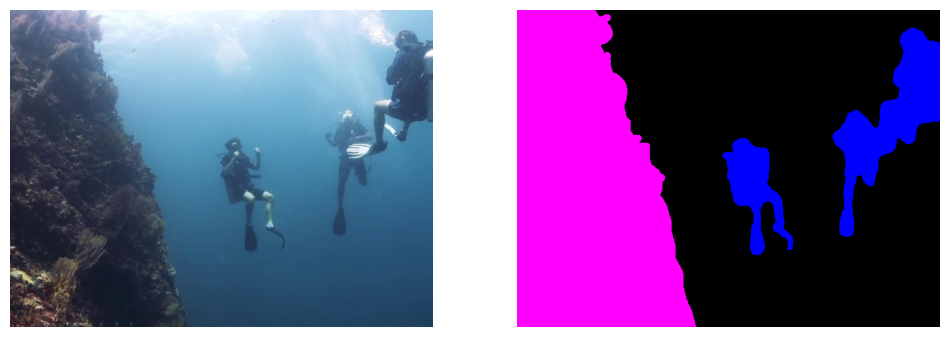

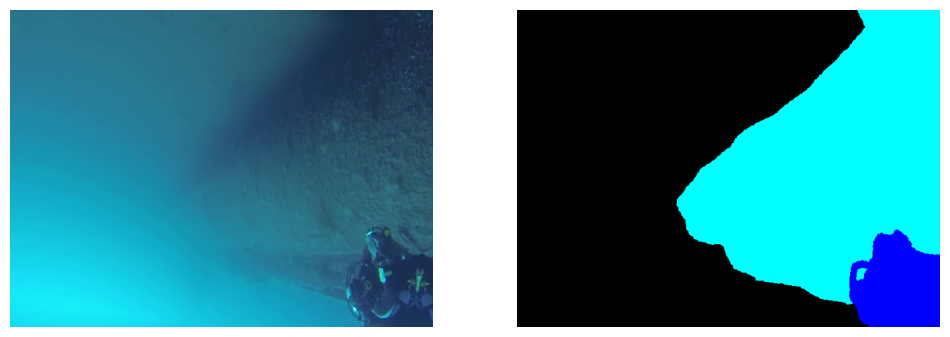

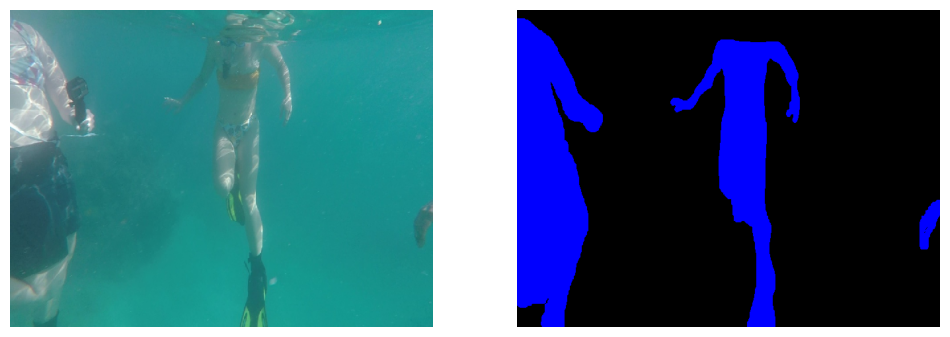

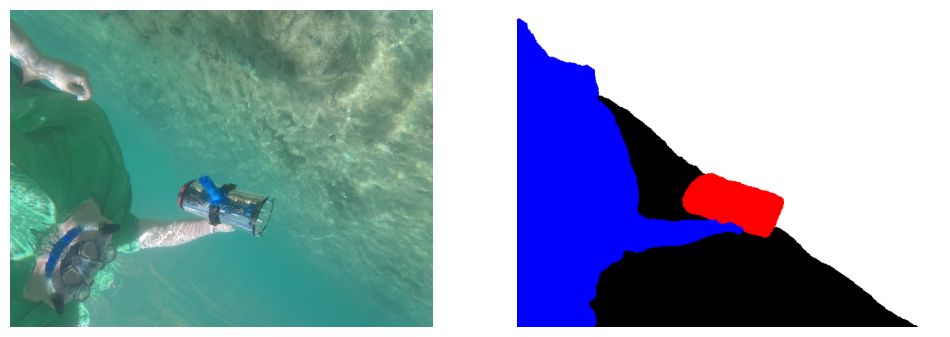

In [184]:
batch = train_generator[0]
images, masks = batch

print('Training image batch shape:', images.shape)
print('Training mask batch shape:', masks.shape)
print('Number of batches in training set:', len(train_generator))
print('Number of batches in validation set:', len(val_generator))

for i, (img, mask) in enumerate(zip(images, masks)):
    if i > 4: break
    plt.figure(figsize=(12, 12))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(label_to_rgb(mask, class_codes))
    plt.axis('off')
    plt.show()

In [44]:
# Define metrics
iou = tf.keras.metrics.IoU(num_classes=num_classes, target_class_ids=class_codes.keys())
mean_iou = tf.keras.metrics.MeanIoU(num_classes=num_classes)


In [63]:
model = UNet(input_shape=image_shape, n_classes=num_classes, n_filters=16)
model.compile(
    optimizer='adam',
    loss=jaccard_coef_loss,
    metrics=['accuracy', iou, mean_iou, jaccard_coef, dice_coef],
)
# tf.keras.utils.plot_model(model, show_shapes=True)
# model.summary()

In [64]:
epochs = 10

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    steps_per_epoch=len(train_generator),
    validation_steps=len(val_generator),
    callbacks=[
        ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1),
        EarlyStopping(monitor='val_loss', patience=5, verbose=1),
    ],
    verbose=1,
)

Epoch 1/10
3/3 [==============================] - 39s 11s/step - loss: -0.0585 - accuracy: 0.0830 - io_u_8: 0.4375 - mean_io_u_8: 0.4375 - jaccard_coef: 0.0585 - dice_coef: 0.1105 - val_loss: -0.0642 - val_accuracy: 0.0974 - val_io_u_8: 0.4375 - val_mean_io_u_8: 0.4375 - val_jaccard_coef: 0.0642 - val_dice_coef: 0.1206 - lr: 0.0010
Epoch 2/10
3/3 [==============================] - 30s 11s/step - loss: -0.0760 - accuracy: 0.1783 - io_u_8: 0.4375 - mean_io_u_8: 0.4375 - jaccard_coef: 0.0760 - dice_coef: 0.1412 - val_loss: -0.0621 - val_accuracy: 0.0878 - val_io_u_8: 0.4375 - val_mean_io_u_8: 0.4375 - val_jaccard_coef: 0.0621 - val_dice_coef: 0.1169 - lr: 0.0010
Epoch 3/10
3/3 [==============================] - 34s 12s/step - loss: -0.0883 - accuracy: 0.3103 - io_u_8: 0.4375 - mean_io_u_8: 0.4375 - jaccard_coef: 0.0883 - dice_coef: 0.1623 - val_loss: -0.0617 - val_accuracy: 0.0737 - val_io_u_8: 0.4375 - val_mean_io_u_8: 0.4375 - val_jaccard_coef: 0.0617 - val_dice_coef: 0.1162 - lr: 0.001

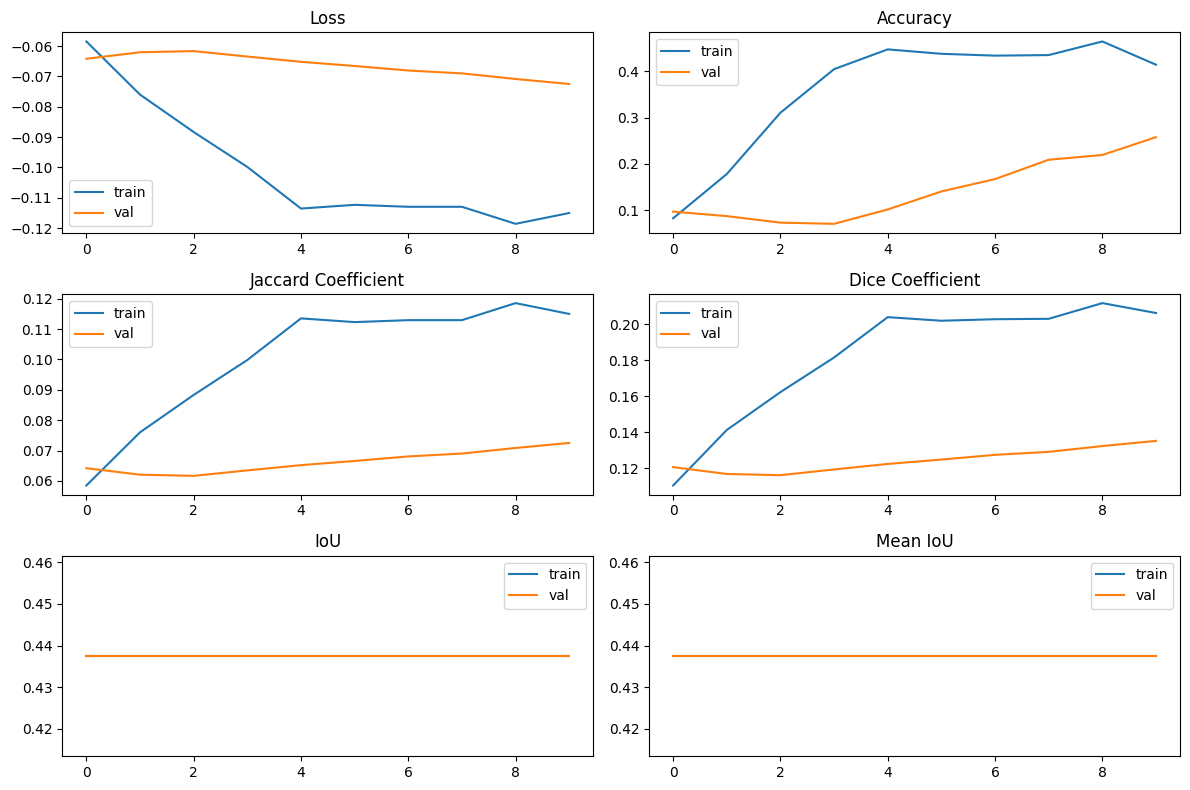

In [72]:
plt.figure(figsize=(12, 8))
plt.subplot(321)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title('Loss')
plt.subplot(322)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title('Accuracy')
plt.subplot(323)
plt.plot(history.history['jaccard_coef'], label='train')
plt.plot(history.history['val_jaccard_coef'], label='val')
plt.legend()
plt.title('Jaccard Coefficient')
plt.subplot(324)
plt.plot(history.history['dice_coef'], label='train')
plt.plot(history.history['val_dice_coef'], label='val')
plt.legend()
plt.title('Dice Coefficient')
plt.subplot(325)
iou_name = [k for k in history.history.keys() if k.startswith('io')][0]
plt.plot(history.history[iou_name], label='train')
plt.plot(history.history[f'val_{iou_name}'], label='val')
plt.legend()
plt.title('IoU')
plt.subplot(326)
iou_name = [k for k in history.history.keys() if k.startswith('mean')][0]
plt.plot(history.history[iou_name], label='train')
plt.plot(history.history[f'val_{iou_name}'], label='val')
plt.legend()
plt.title('Mean IoU')
plt.tight_layout()
plt.show()

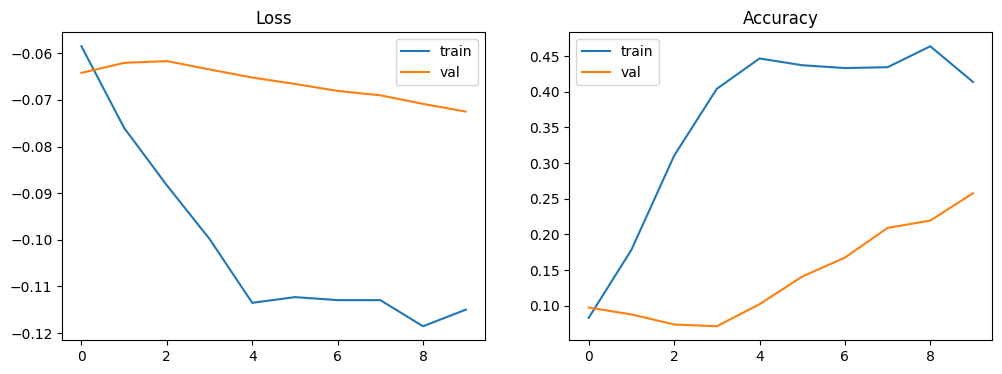

In [65]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(121)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title('Loss')
plt.subplot(122)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title('Accuracy')
plt.show()

In [149]:
# save model
model.save('models/basic-unet-model.h5')

In [150]:
# load best weights
model.load_weights('models/first-unet-model.h5')

In [151]:
test = train_generator[0]

predictions = model.predict(test[0])
predictions.shape

1/1 [==============================] - 3s 3s/step


(4, 480, 640, 8)

predictions.shape = (4, 480, 640, 8)
y_pred.shape = (4, 480, 640)
uni_y_pred = array([0, 1, 3, 5, 6, 7], dtype=int64)
img.shape = (480, 640, 3)
true.shape = (480, 640, 8)
uni_true = array([0., 1.], dtype=float32)
pred.shape = (480, 640)
uni_pred = array([0, 1, 3, 5, 6, 7], dtype=int64)
Reconstructed mask shape: (480, 640, 3)


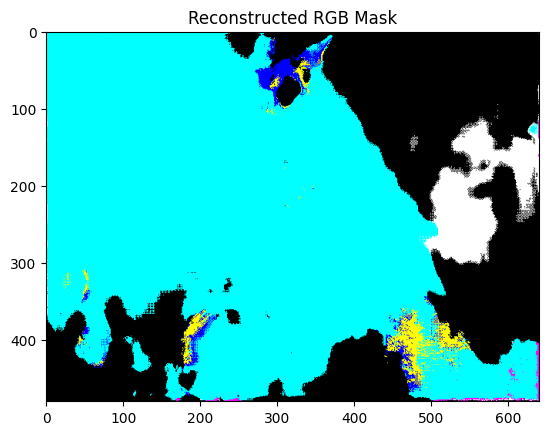

In [152]:
y_pred = np.argmax(predictions, axis=-1)
# y_pred = np.expand_dims(y_pred, axis=-1)
uni_y_pred = np.unique(y_pred)
pred = y_pred[0]
uni_pred = np.unique(pred)

img, true = test[0][0], test[1][0]
uni_true = np.unique(true)

print(f'{predictions.shape = }')
print(f'{y_pred.shape = }')
print(f'{uni_y_pred = }')
print(f'{img.shape = }')
print(f'{true.shape = }')
print(f'{uni_true = }')
print(f'{pred.shape = }')
print(f'{uni_pred = }')

rgb_mask = label_to_rgb(pred, class_codes, one_hot=False)
print('Reconstructed mask shape:', rgb_mask.shape)
plt.imshow(rgb_mask)
plt.title('Reconstructed RGB Mask')
plt.show()

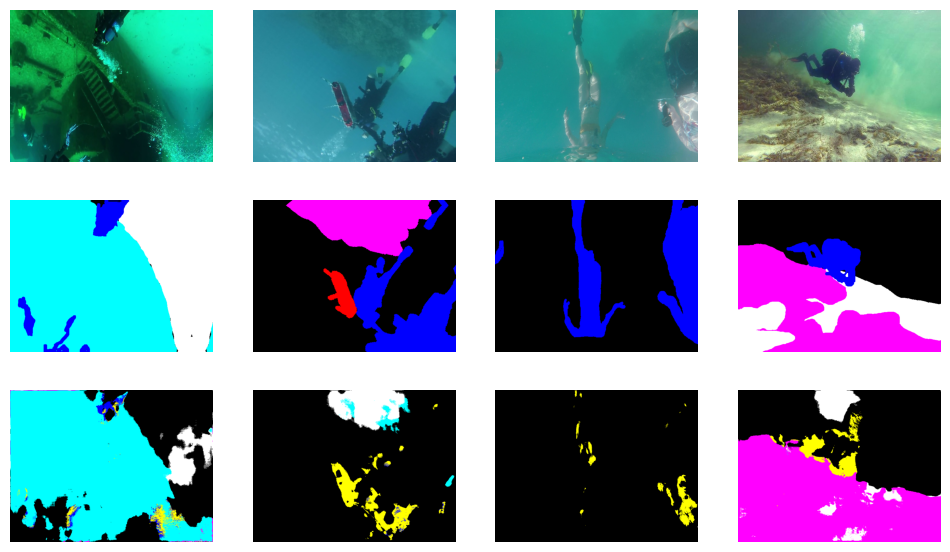

In [153]:
y_pred = np.argmax(predictions, axis=-1)

plt.subplots(3, 4, figsize=(12, 7))
for i, pred in enumerate(y_pred[:4]):
    img = test[0][i]
    true = test[1][i]
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(3, 4, i + 5)
    plt.imshow(label_to_rgb(true, class_codes, one_hot=True))
    plt.axis('off')
    plt.subplot(3, 4, i + 9)
    plt.imshow(label_to_rgb(pred, class_codes, one_hot=False))
    plt.axis('off')
plt.show()